# Tarea 2 · Parte 2: de los modelos base a la extracción estructurada

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de evaluación** | 24 de octubre de 2026 |
| **Muestra** | 10 documentos (3 impresos, 4 fotos, 3 manuscritos) y 10 clips (calle, marcha, fiesta patronal, lectura), tomados del corpus de la Parte 1. No se recolectaron datos nuevos. |
| **Referencias** | Transcripción manual hecha por el autor **desde el original** (imagen o audio), no corrigiendo la salida de un modelo: `datos/referencias/` (local) → columna `texto_referencia` |
| **OCR** | Base: PaddleOCR PP-OCRv6 medium. Alternativo: EasyOCR (CRAFT + latin_g2) |
| **ASR** | Base: faster-whisper `small` (CPU int8, VAD). Alternativo: Qwen3-ASR 0.6B (CPU float32, VAD) |
| **LLM** | Gemini 3.5 Flash-Lite (temperatura 0, salida JSON con esquema) |

**Regla de juego:** las configuraciones de los cuatro modelos se escribieron en `modelos/configuracion.json` y se versionaron (commit `da478cd`, «fijar EasyOCR, Qwen3-ASR 0.6B y Gemini antes de medir CER/WER») **antes** de calcular cualquier métrica. Después de ver los resultados no se tocó ningún parámetro. Todos los modelos se comparan sobre los mismos 10 + 10 archivos.

La inferencia pesada se corrió por tandas desde la terminal con `evaluacion.py` (`easyocr`, `qwen`, `llm`). Las salidas crudas quedan en caché en `datos/raw/` (no versionado), y este notebook las lee para medir, comparar y exportar.

In [1]:
import json
import re
import sys
import warnings

warnings.filterwarnings("ignore")

import jiwer
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import Markdown, display

import evaluacion as ev
import voz

pio.renderers.default = "plotly_mimetype+png"
pio.defaults.default_width, pio.defaults.default_height = 1000, 500
pd.set_option("display.max_colwidth", 120)

DATOS = ev.DATOS
COLORES = {"PaddleOCR": "#2a78d6", "EasyOCR": "#eb6834", "faster-whisper small": "#2a78d6", "Qwen3-ASR 0.6B": "#eb6834"}
CONFIG = json.loads((ev.CARPETA / "modelos/configuracion.json").read_text(encoding="utf-8"))

import easyocr, faster_whisper, google.genai, paddleocr, transformers
print(f"Python {sys.version.split()[0]} · PaddleOCR {paddleocr.__version__} · EasyOCR {easyocr.__version__} · "
      f"faster-whisper {faster_whisper.__version__} · transformers {transformers.__version__} · google-genai {google.genai.__version__}")
print("Configuración fijada:", CONFIG["fijada"])
pd.DataFrame([
    ("OCR", "base", CONFIG["ocr"]["base"]["modelo"]),
    ("OCR", "alternativo", CONFIG["ocr"]["alternativo"]["modelo"]),
    ("ASR", "base", CONFIG["asr"]["base"]["modelo"]),
    ("ASR", "alternativo", CONFIG["asr"]["alternativo"]["modelo"]),
    ("LLM", "extracción", f"{CONFIG['llm']['modelos'][0]} (temperatura {CONFIG['llm']['temperatura']}, {CONFIG['llm']['salida']})"),
], columns=["modalidad", "rol", "modelo y configuración"])

Python 3.12.15 · PaddleOCR 3.7.0 · EasyOCR 1.7.2 · faster-whisper 1.2.1 · transformers 5.20.2 · google-genai 2.33.0
Configuración fijada: 2026-10-24, antes de calcular CER/WER sobre la muestra


,modalidad,rol,modelo y configuración
0,OCR,base,"PaddleOCR 3.7.0 (PP-OCRv6_medium_det + PP-OCRv6_medium_rec, CPU, sin preprocesamiento)"
1,OCR,alternativo,"EasyOCR 1.7.2 (CRAFT + latin_g2, lang=es, CPU, valores por defecto)"
2,ASR,base,"faster-whisper 1.2.1 small (CPU int8, beam 5, VAD Silero on, idioma=es)"
3,ASR,alternativo,"Qwen3-ASR 0.6B (transformers, CPU float32, VAD Silero, idioma=es)"
4,LLM,extracción,"gemini-3.5-flash-lite (temperatura 0, JSON con esquema (pydantic))"


## 1. Muestra de evaluación y referencias manuales

La muestra se eligió en la Parte 1 (día 2), antes de correr cualquier modelo alternativo:

- **Documentos:** 3 impresos (doc_001, 002, 008), 4 fotos con sombra o inclinación (009, 012, 013, 015) y 3 manuscritos (020, 022, 024). Quedaron fuera los manuscritos 017 a 019, que el autor no pudo leer con seguridad: una referencia dudosa mediría al transcriptor, no al modelo.
- **Clips:** 10 de 6 fuentes y condiciones distintas: entrevistas en la calle, en marchas con ruido de multitud, en una fiesta patronal de Áncash, una de estudiantes de la UNMSM y lecturas de artículos.

En las referencias, el autor marcó los turnos (`h1:`, `h2:`), lo ilegible o inaudible (`[?]`) y algunos sonidos (`[risas]`). Contienen nombres reales, así que **se seudonimizan con el mismo mapa de la Parte 1** antes de publicarlas o de medir. Antes de publicar, se revisaron con el NER y con una búsqueda de cada parte de cada nombre privado en **todos** los textos nuevos: referencias, EasyOCR, Qwen3-ASR y salidas del LLM. Aparecieron tres variantes que la comparación difusa no atrapaba, y se agregaron como alias en el mapa local (que no se versiona), con la misma etiqueta:
- en la referencia de clip_002, el nombre de una entrevistada escrito con dos erratas (parecido de 74 < 80);
- en el texto de EasyOCR de doc_003, el nombre del homenajeado partido en dos líneas;
- en la transcripción de Qwen3-ASR de clip_009, el nombre del entrevistador escuchado con otra grafía.

Así, cada modelo se mide y se publica con el mismo tratamiento de privacidad. El procedimiento automático no basta: la revisión humana encontró lo que el umbral dejaba pasar.

In [2]:
REEMPLAZOS = json.loads((ev.RAW / "seudonimos.json").read_text(encoding="utf-8"))   # no versionado: nombres reales
seud = lambda i, t: voz.seudonimizar(t, REEMPLAZOS.get(i, {}))

docs = pd.read_csv(DATOS / "documentos.csv")
clips = pd.read_csv(DATOS / "transcripciones.csv")
D, C = docs.set_index("id"), clips.set_index("id")

# referencia publicada (seudonimizada, tal como la escribió el autor) y referencia para medir (sin marcas)
ref_publicada = {i: seud(i, ev.leer_referencia(i)) for i in ev.MUESTRA_DOCS + ev.MUESTRA_CLIPS}
ref = {i: ev.limpiar_referencia(t) for i, t in ref_publicada.items()}

muestra = pd.DataFrame({
    "id": list(ref),
    "modalidad": ["documento"] * 10 + ["audio"] * 10,
    "tipo o condición": [D.tipo[i] for i in ev.MUESTRA_DOCS] + [C.descripcion[i] for i in ev.MUESTRA_CLIPS],
    "palabras_ref": [len(voz.normalizar(ref[i]).split()) for i in ref],
    "caracteres_ref": [len(voz.normalizar(ref[i])) for i in ref],
    "marcas_[?]": [ref_publicada[i].count("[?]") for i in ref],
})
print(f"Referencias manuales: {len(ref)} · {muestra.palabras_ref.sum():,} palabras en total "
      f"({muestra.query('modalidad == \"documento\"').palabras_ref.sum():,} de documentos, "
      f"{muestra.query('modalidad == \"audio\"').palabras_ref.sum():,} de audio)")
muestra

Referencias manuales: 20 · 3,126 palabras en total (1,065 de documentos, 2,061 de audio)


,id,modalidad,tipo o condición,palabras_ref,caracteres_ref,marcas_[?]
0,doc_001,documento,impreso,162,1011,0
1,doc_002,documento,impreso,91,554,2
2,doc_008,documento,impreso,249,1393,0
3,doc_009,documento,foto,60,339,0
4,doc_012,documento,foto,31,170,0
5,doc_013,documento,foto,39,223,0
6,doc_015,documento,foto,133,842,0
7,doc_020,documento,manuscrito,60,359,1
8,doc_022,documento,manuscrito,202,1131,0
9,doc_024,documento,manuscrito,38,199,2


### Criterio de normalización (el mismo para referencias y modelos)

1. **Referencia:** se quitan las marcas de turno (`h1:`, `h2.`) y las anotaciones entre corchetes (`[?]`, `[risas]`), que no son texto leído ni palabras habladas.
2. **Hipótesis:** se quitan las marcas `[HABLANTE_n]` de la diarización.
3. **Ambas:** se seudonimizan con el mismo mapa. Una etiqueta como `[ENTREVISTADA_7]` cuenta como una palabra porque reemplaza un nombre que sí se dijo. Luego se aplica `voz.normalizar`: minúsculas, sin puntuación y sin espacios repetidos. **Las tildes se conservan**, porque en español cambian palabras ("Perú" frente a "peru").
4. **Agregado:** el CER y el WER de cada modelo son **de corpus**: errores totales entre el largo total de las diez referencias. Así un documento corto no pesa igual que uno largo. También se reporta el valor por archivo.

El CER y el WER penalizan el **orden**: si un OCR lee bien las palabras pero en otro orden, el error sube. Es lo correcto para un archivo buscable por frases, y se discute en los casos difíciles.

In [3]:
i = "doc_012"
print("Referencia normalizada :", voz.normalizar(ref[i])[:150])
print("PaddleOCR normalizado  :", voz.normalizar(D.texto_ocr[i])[:150])

Referencia normalizada : se inauguraron los mercados mayorista y minorista siendo presidente de la republica el sr dr manuel prado y alcalde de lima don luis gallo porras lima
PaddleOCR normalizado  : seinauguraronlos mercados mayorista yminorista siendo presidente de la republica elsr dr manuel prado y alcalde de lima donluisgalloporras lima 26 jul


## 2. Línea base sin ajuste: PaddleOCR y faster-whisper `small`

In [4]:
def textos_easyocr(i):
    return seud(i, "\n".join(ev.easyocr_documento(i)["lineas"]))


def textos_qwen(i):
    return seud(i, " ".join(s["texto"] for s in ev.qwen_clip(i)["segmentos"]))


hip = {
    "PaddleOCR": {i: D.texto_ocr[i] for i in ev.MUESTRA_DOCS},                       # ya seudonimizado en la Parte 1
    "EasyOCR": {i: textos_easyocr(i) for i in ev.MUESTRA_DOCS},
    "faster-whisper small": {i: ev.limpiar_hipotesis(C.texto_asr[i]) for i in ev.MUESTRA_CLIPS},
    "Qwen3-ASR 0.6B": {i: textos_qwen(i) for i in ev.MUESTRA_CLIPS},
}
ref_docs = {i: ref[i] for i in ev.MUESTRA_DOCS}
ref_clips = {i: ref[i] for i in ev.MUESTRA_CLIPS}


def de_corpus(referencias, hipotesis, metrica):
    ids = list(referencias)
    return metrica([referencias[i] for i in ids], [hipotesis[i] for i in ids])


cer_base = de_corpus(ref_docs, hip["PaddleOCR"], voz.cer)
wer_base = de_corpus(ref_clips, hip["faster-whisper small"], voz.wer)
print(f"LÍNEA BASE · CER PaddleOCR (10 documentos): {cer_base:.3f} · WER faster-whisper small (10 clips): {wer_base:.3f}")

LÍNEA BASE · CER PaddleOCR (10 documentos): 0.091 · WER faster-whisper small (10 clips): 0.218

## 3. Modelos alternativos sobre las mismas muestras

In [5]:
filas = []
for modelo in ["PaddleOCR", "EasyOCR"]:
    for i in ev.MUESTRA_DOCS:
        seg = D.segundos_ocr[i] if modelo == "PaddleOCR" else ev.easyocr_documento(i)["segundos"]
        filas.append({"id": i, "modalidad": "documento", "tipo": D.tipo[i], "modelo": modelo, "metrica": "CER",
                      "valor": voz.cer([ref[i]], [hip[modelo][i]]), "segundos": seg, "factor_tiempo_real": None})
for modelo in ["faster-whisper small", "Qwen3-ASR 0.6B"]:
    for i in ev.MUESTRA_CLIPS:
        seg = C.segundos_asr[i] if modelo == "faster-whisper small" else ev.qwen_clip(i)["segundos_asr"]
        filas.append({"id": i, "modalidad": "audio", "tipo": C.descripcion[i], "modelo": modelo, "metrica": "WER",
                      "valor": voz.wer([ref[i]], [hip[modelo][i]]), "segundos": seg,
                      "factor_tiempo_real": seg / C.duracion_seg[i]})
metricas = pd.DataFrame(filas)

corpus = pd.DataFrame([
    {"modalidad": "documento", "modelo": m, "métrica": "CER", "valor (corpus)": de_corpus(ref_docs, hip[m], voz.cer),
     "WER de palabras": de_corpus(ref_docs, hip[m], voz.wer),
     "segundos por documento": metricas.query("modelo == @m").segundos.mean(), "factor de tiempo real": None}
    for m in ["PaddleOCR", "EasyOCR"]] + [
    {"modalidad": "audio", "modelo": m, "métrica": "WER", "valor (corpus)": de_corpus(ref_clips, hip[m], voz.wer),
     "WER de palabras": de_corpus(ref_clips, hip[m], voz.wer),
     "segundos por documento": None,
     "factor de tiempo real": metricas.query("modelo == @m").segundos.sum() / C.duracion_seg[ev.MUESTRA_CLIPS].sum()}
    for m in ["faster-whisper small", "Qwen3-ASR 0.6B"]])
corpus.round(3)

,modalidad,modelo,métrica,valor (corpus),WER de palabras,segundos por documento,factor de tiempo real
0,documento,PaddleOCR,CER,0.091,0.248,27.64,NaN
1,documento,EasyOCR,CER,0.300,0.580,17.05,NaN
2,audio,faster-whisper small,WER,0.218,0.218,NaN,0.362
3,audio,Qwen3-ASR 0.6B,WER,0.228,0.228,NaN,0.844


La columna «WER de palabras» de los documentos muestra un efecto que el CER esconde: PaddleOCR **pega palabras** que en la imagen están separadas por poco espacio. En doc_012 lee "seinauguraronlos" en vez de "se inauguraron los". Cada palabra pegada cuenta como varios errores de palabra, aunque solo falte un espacio. Para un buscador por palabras clave, eso pesa más de lo que sugiere un CER de 0,09.

In [6]:
BASE = {"PaddleOCR": "base", "faster-whisper small": "base", "EasyOCR": "alternativo", "Qwen3-ASR 0.6B": "alternativo"}
por_archivo = (metricas.assign(rol=metricas.modelo.map(BASE))
               .pivot_table(index=["modalidad", "metrica", "id", "tipo"], columns="rol", values="valor")[["base", "alternativo"]])
por_archivo["mejor"] = (por_archivo.base - por_archivo.alternativo).map(lambda d: "base" if d < 0 else ("alternativo" if d > 0 else "empate"))
print("base = PaddleOCR / faster-whisper small · alternativo = EasyOCR / Qwen3-ASR 0.6B")
print(por_archivo.groupby(level="modalidad").mejor.value_counts().to_string())
por_archivo.round(3)

base = PaddleOCR / faster-whisper small · alternativo = EasyOCR / Qwen3-ASR 0.6B
modalidad  mejor      
audio      base            6
           alternativo     3
           empate          1
documento  base           10


rol                                                                        base  \
modalidad metrica id       tipo                                                   
audio     WER     clip_001 entrevista en la calle                         0.268   
                  clip_002 entrevista en la calle, varias hablantes       0.189   
                  clip_003 entrevista durante un partido, ruido de fondo  0.435   
                  clip_006 entrevista grabada por estudiante UNMSM        0.215   
                  clip_008 entrevista en una marcha, ruido de multitud    0.278   
                  clip_009 entrevista en una marcha, ruido de multitud    0.199   
                  clip_013 entrevista en una fiesta patronal (Áncash)     0.332   
                  clip_015 entrevista en una fiesta patronal (Áncash)     0.066   
                  clip_016 lectura de artículo de Wikipedia               0.160   
                  clip_020 lectura de artículo de Wikipedia               0.071   
documento CER     doc_001  impreso                                        0.039   
                  doc_002  impreso                                        0.038   
                  doc_008  impreso                                        0.042   
                  doc_009  foto                                           0.006   
                  doc_012  foto                                           0.065   
                  doc_013  foto                                           0.013   
                  doc_015  foto                                           0.039   
                  doc_020  manuscrito                                     0.159   
                  doc_022  manuscrito                                     0.213   
                  doc_024  manuscrito                                     0.513   

rol                                                                       alternativo  \
modalidad metrica id       tipo                                                         
audio     WER     clip_001 entrevista en la calle                               0.303   
                  clip_002 entrevista en la calle, varias hablantes             0.220   
                  clip_003 entrevista durante un partido, ruido de fondo        0.329   
                  clip_006 entrevista grabada por estudiante UNMSM              0.249   
                  clip_008 entrevista en una marcha, ruido de multitud          0.278   
                  clip_009 entrevista en una marcha, ruido de multitud          0.131   
                  clip_013 entrevista en una fiesta patronal (Áncash)           0.300   
                  clip_015 entrevista en una fiesta patronal (Áncash)           0.132   
                  clip_016 lectura de artículo de Wikipedia                     0.194   
                  clip_020 lectura de artículo de Wikipedia                     0.104   
documento CER     doc_001  impreso                                              0.064   
                  doc_002  impreso                                              0.123   
                  doc_008  impreso                                              0.259   
                  doc_009  foto                                                 0.018   
                  doc_012  foto                                                 0.141   
                  doc_013  foto                                                 0.619   
                  doc_015  foto                                                 0.058   
                  doc_020  manuscrito                                           0.641   
                  doc_022  manuscrito                                           0.681   
                  doc_024  manuscrito                                           0.779   

rol                                                                             mejor  
modalidad metrica id       tipo                                                        
audio     WER     clip_001 entrevista 

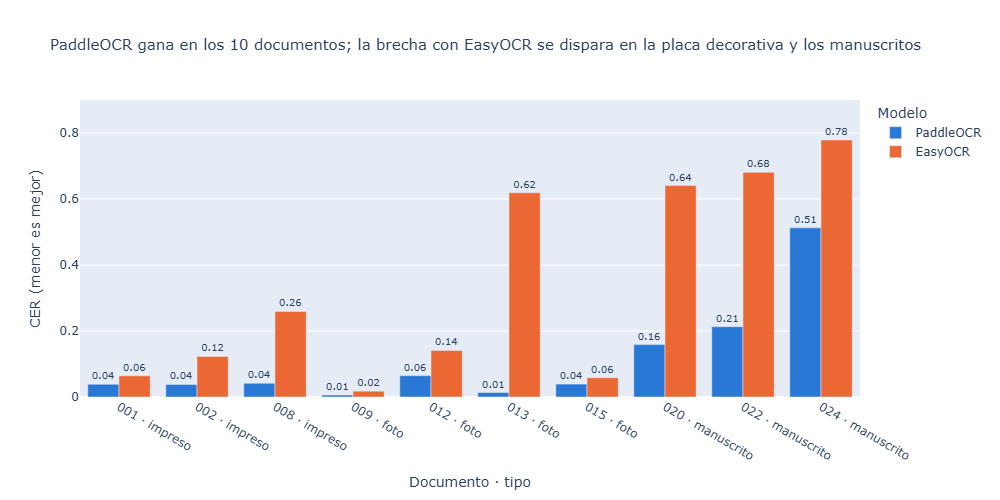

In [7]:
d = metricas.query("modalidad == 'documento'").copy()
d["etiqueta"] = d.id.str.replace("doc_", "") + " · " + d.tipo
fig = px.bar(d, x="etiqueta", y="valor", color="modelo", barmode="group", color_discrete_map=COLORES,
             text=d.valor.map(lambda v: f"{v:.2f}"),
             title="PaddleOCR gana en los 10 documentos; la brecha con EasyOCR se dispara en la placa decorativa y los manuscritos",
             labels={"etiqueta": "Documento · tipo", "valor": "CER (menor es mejor)", "modelo": "Modelo"})
fig.update_traces(textposition="outside", textfont_size=10).update_layout(title_font_size=15, yaxis_range=[0, 0.9])
fig.show()

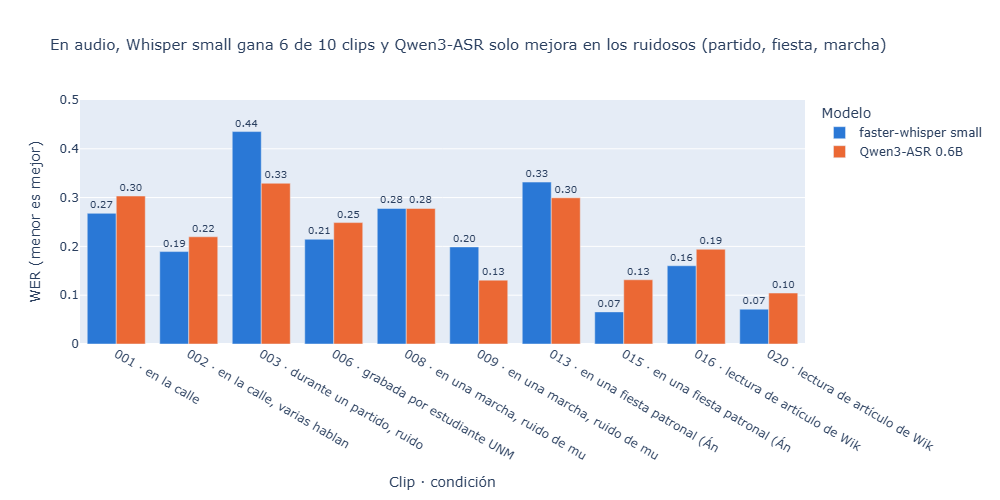

In [8]:
a = metricas.query("modalidad == 'audio'").copy()
a["etiqueta"] = a.id.str.replace("clip_", "") + " · " + a.tipo.str.replace("entrevista ", "").str[:26]
fig = px.bar(a, x="etiqueta", y="valor", color="modelo", barmode="group", color_discrete_map=COLORES,
             text=a.valor.map(lambda v: f"{v:.2f}"),
             title="En audio, Whisper small gana 6 de 10 clips y Qwen3-ASR solo mejora en los ruidosos (partido, fiesta, marcha)",
             labels={"etiqueta": "Clip · condición", "valor": "WER (menor es mejor)", "modelo": "Modelo"})
fig.update_traces(textposition="outside", textfont_size=10).update_layout(title_font_size=15, yaxis_range=[0, 0.5])
fig.show()

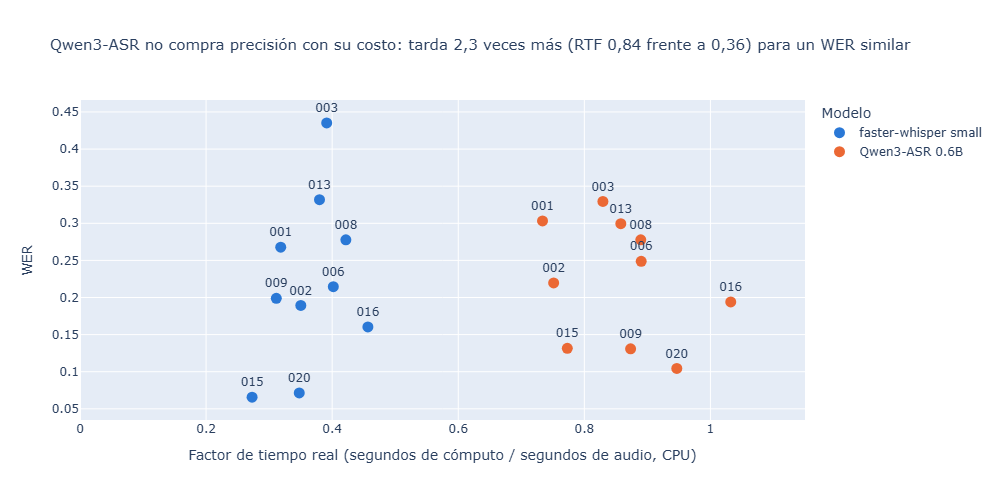

In [9]:
fig = px.scatter(a, x="factor_tiempo_real", y="valor", color="modelo", color_discrete_map=COLORES, text=a.id.str.replace("clip_", ""),
                 title="Qwen3-ASR no compra precisión con su costo: tarda 2,3 veces más (RTF 0,84 frente a 0,36) para un WER similar",
                 labels={"factor_tiempo_real": "Factor de tiempo real (segundos de cómputo / segundos de audio, CPU)",
                         "valor": "WER", "modelo": "Modelo"})
fig.update_traces(textposition="top center", marker_size=11).update_layout(title_font_size=15, xaxis_range=[0, 1.15])
fig.show()

## 4. Casos difíciles

### 4.1 Por tipo de documento y por condición de grabación

In [10]:
def grupo_audio(desc):
    for clave, nombre in [("calle", "calle"), ("marcha", "marcha (multitud)"), ("partido", "partido (ruido)"),
                          ("fiesta", "fiesta patronal"), ("lectura", "lectura"), ("UNMSM", "estudiante UNMSM")]:
        if clave in desc:
            return nombre
    return "otro"


filas = []
for tipo in ["impreso", "foto", "manuscrito"]:
    ids = [i for i in ev.MUESTRA_DOCS if D.tipo[i] == tipo]
    filas.append({"modalidad": "documento", "grupo": tipo, "n": len(ids),
                  "base": voz.cer([ref[i] for i in ids], [hip["PaddleOCR"][i] for i in ids]),
                  "alternativo": voz.cer([ref[i] for i in ids], [hip["EasyOCR"][i] for i in ids])})
grupos = pd.Series({i: grupo_audio(C.descripcion[i]) for i in ev.MUESTRA_CLIPS})
for g, ids in grupos.groupby(grupos).groups.items():
    ids = list(ids)
    filas.append({"modalidad": "audio", "grupo": g, "n": len(ids),
                  "base": voz.wer([ref[i] for i in ids], [hip["faster-whisper small"][i] for i in ids]),
                  "alternativo": voz.wer([ref[i] for i in ids], [hip["Qwen3-ASR 0.6B"][i] for i in ids])})
print("Documentos: CER (base PaddleOCR, alternativo EasyOCR) · Audio: WER (base faster-whisper small, alternativo Qwen3-ASR 0.6B)")
pd.DataFrame(filas).set_index(["modalidad", "grupo"]).round(3)

Documentos: CER (base PaddleOCR, alternativo EasyOCR) · Audio: WER (base faster-whisper small, alternativo Qwen3-ASR 0.6B)


n   base  alternativo
modalidad grupo                                   
documento impreso            3  0.040        0.167
          foto               4  0.031        0.138
          manuscrito         3  0.237        0.684
audio     calle              2  0.224        0.256
          estudiante UNMSM   1  0.215        0.249
          fiesta patronal    2  0.263        0.256
          lectura            2  0.122        0.155
          marcha (multitud)  2  0.235        0.198
          partido (ruido)    1  0.435        0.329

### 4.2 Manuscritos: el punto débil de los dos OCR

El CER de PaddleOCR va de 0,03–0,04 en impresos y fotos a **0,24 en manuscritos**: de 6 a 8 veces más. EasyOCR se desploma a 0,68, es decir, devuelve más ruido que texto. La carta de Piérola (doc_020, 1894) muestra por qué:

In [11]:
i = "doc_020"
for nombre, texto in [("Referencia", ref[i]), ("PaddleOCR", hip["PaddleOCR"][i]), ("EasyOCR", hip["EasyOCR"][i])]:
    print(f"{nombre:<11}", " | ".join(texto.splitlines()[:4])[:230])
print(f"\nCER doc_020 · PaddleOCR {voz.cer([ref[i]], [hip['PaddleOCR'][i]]):.3f} · EasyOCR {voz.cer([ref[i]], [hip['EasyOCR'][i]]):.3f}")

Referencia  Lima, Agosto 10 de 1894 | Sr. S.M. Rodriguez R. | Prefecto del Depart. 3 Lambayeque | Mi querido Sr. Prefeto:
PaddleOCR   $30 | Sr I.M. Rodriguer R. | Prefecto del Dept | Lambayeque
EasyOCR     22 | 2 189} | 090). | 3

CER doc_020 · PaddleOCR 0.159 · EasyOCR 0.641


PaddleOCR sigue las líneas y lee bien las palabras comunes, pero se equivoca con la caligrafía cursiva, los nexos entre letras y las abreviaturas de época ("Depart.", "Sr."). EasyOCR no declara soporte para escritura a mano (figura como pendiente en su hoja de ruta): inventa letras y números ("189 090 3") donde hay trazos cursivos. El peor caso es doc_024 (CER 0,51 incluso con PaddleOCR), una carta cursiva del siglo XIX en la que el autor también marcó palabras ilegibles con `[?]`. Ahí el límite no está solo en el modelo, sino en la legibilidad del original.

### 4.3 La foto de una placa decorativa: EasyOCR desordena y confunde letras

In [12]:
i = "doc_013"
orden = lambda s: " ".join(sorted(voz.normalizar(s).split()))
print("Referencia :", voz.normalizar(ref[i])[:140])
print("EasyOCR    :", voz.normalizar(hip["EasyOCR"][i])[:140])
print(f"\nCER EasyOCR {voz.cer([ref[i]], [hip['EasyOCR'][i]]):.3f} · con las palabras ordenadas alfabéticamente (sin efecto del orden): "
      f"{jiwer.cer(orden(ref[i]), orden(hip['EasyOCR'][i])):.3f} · PaddleOCR {voz.cer([ref[i]], [hip['PaddleOCR'][i]]):.3f}")

Referencia : este teatro fue reformado y mejorado a iniciativa de la colectividad española en el perú con la colaboración de la embajada de españa en lim
EasyOCR    : fue_ y mejorado a en de a la con a de de en y con la del de e de 2010 ste teatro reformado golectioidad gspañola iniciatioa e ferú êmbajada 

CER EasyOCR 0.619 · con las palabras ordenadas alfabéticamente (sin efecto del orden): 0.578 · PaddleOCR 0.013


Con doc_013, la placa conmemorativa de la colectividad española, EasyOCR comete dos errores a la vez. Primero, agrupa las cajas de palabras cortas ("y", "a", "de", "la") antes que las largas, así que el texto sale **desordenado**. Segundo, confunde las letras de la tipografía decorativa: lee "golectioidad gspañola" donde dice "colectividad española" y "êmbajada" donde dice "embajada". Aun ordenando las palabras, el CER solo baja de 0,62 a 0,58: el error principal está en las letras. PaddleOCR lee la misma placa con CER 0,01.

### 4.4 Audio con ruido y con música

In [13]:
i = "clip_014"
fw = ev.limpiar_hipotesis(C.texto_asr[i])
qw = textos_qwen(i)
print(f"{i}: {C.duracion_seg[i]} s de audio, de los cuales solo {C.voz_seg[i]} s tienen voz según Silero VAD "
      f"({C.voz_seg[i] / C.duracion_seg[i]:.0%}); el resto es la banda de música de la fiesta patronal.")
print(f"\nfaster-whisper small ({len(fw.split())} palabras): {fw.strip()}")
print(f"\nQwen3-ASR 0.6B ({len(qw.split())} palabras): {qw}")

clip_014: 98.3 s de audio, de los cuales solo 10.6 s tienen voz según Silero VAD (11%); el resto es la banda de música de la fiesta patronal.

faster-whisper small (30 palabras): ¿Como se vive en ese momento el dolor? Pues sí, la imagen se celebra ya en la sierra en Chuyas, pero acá ya, bueno, para no creer...
  ¿Sólo de venir?

Qwen3-ASR 0.6B (30 palabras): Sí, vamos. chuyas verdad sí está pertenecido sí y cómo cómo se vive en ese momento en sí la imagen se celebra ya ingresieron chubias pero acá bueno pero Venir.


- **Música (clip_014):** sin VAD, Whisper suele **alucinar frases** sobre la música ("Gracias por ver el video", "Suscríbete"). Aquí, con el VAD activado en los dos modelos, ninguno inventó nada: cada uno devuelve unas 30 palabras de los 10,6 s de habla y nada de los 88 s de banda. Whisper produce un texto más legible y con puntuación. Qwen mezcla palabras inventadas sobre los nombres locales ("ingresieron chubias" por "en la sierra en Chuyas"). Este clip no tiene referencia manual, porque la voz apenas se oye, así que el análisis es cualitativo.
- **Ruido de multitud y de estadio:** los peores WER de Whisper están en clip_003 (entrevista durante un partido, 0,43) y clip_013 (fiesta patronal, 0,33). En los dos, Qwen3-ASR baja el error (0,33 y 0,30): su codificador parece más robusto al ruido de fondo. En las marchas (clip_008 y clip_009) empatan o gana Qwen.
- **Habla limpia:** en las lecturas (clip_016, clip_020) y en la entrevista tranquila clip_015, Whisper es claramente mejor (0,07–0,16 frente a 0,10–0,19).
- **Muletillas:** los dos modelos omiten la mayoría de los "eh", "este" y "o sea" que el autor sí transcribió (63 en las referencias frente a unas 22 en cada modelo). Eso suma palabras borradas al WER de ambos por igual: es una diferencia de criterio entre transcripción literal y limpia, no un error de comprensión.
- **Quechua de Huaylas con MMS (bonificación):** no se intentó. El corpus no tiene un clip en quechua con licencia libre y transcripción verificable.

## 5. Extracción estructurada con un LLM

Cada uno de los 48 textos **ya seudonimizados** (25 OCR y 23 ASR) se envió por separado a Gemini 3.5 Flash-Lite con temperatura 0 y una **salida JSON validada con un esquema pydantic**. A la API nunca se le envió un nombre real. El esquema obliga a `null` cuando un dato no aparece y no admite campos extra:

- **Documentos:** `modalidad`, `tema`, `resumen`, `emisor`, `fecha` y `monto` (estos tres, solo si aparecen).
- **Audios:** `modalidad`, `tema`, `resumen`, `numero_hablantes` (solo si el contenido lo sustenta) y `citas_clave` (de 1 a 3 frases copiadas textualmente).

In [14]:
print(ev.PROMPT_DOCUMENTO, "\n\n" + "─" * 80 + "\n")
print(ev.PROMPT_AUDIO)

Eres un archivista peruano. Recibes el texto que un OCR extrajo de un documento
escaneado o fotografiado (impreso, foto de celular o manuscrito, a veces de los siglos XIX o XX).
El OCR comete errores: no los corrijas inventando, y si una parte es ilegible no la reconstruyas.

Devuelve SOLO estos campos, basándote únicamente en el texto:
- modalidad: siempre "documento".
- tema: el asunto principal en pocas palabras (máximo 8).
- resumen: una o dos oraciones con lo que dice el documento.
- emisor: quien firma, escribe o publica el documento, tal como aparece; null si no aparece.
- fecha: la fecha del documento tal como aparece en el texto; null si no aparece.
- monto: una cantidad de dinero con su moneda, tal como aparece; null si no hay ninguna.
Usa null para todo dato ausente. No agregues campos. Las etiquetas como [PERSONA_1] son
seudónimos de personas reales: cópialas tal cual, no intentes adivinar el nombre. 

────────────────────────────────────────────────────────────────────────

In [15]:
textos = ev.textos_publicados()
crudo = {i: json.loads((ev.RAW / "llm" / f"{i}.json").read_text(encoding="utf-8")) for i in textos}
extraccion = pd.DataFrame([{
    "id": i, "modalidad": r["campos"]["modalidad"],
    "campos_json": json.dumps(r["campos"], ensure_ascii=False),
    "modelo_llm": r["modelo_llm"], "fecha": r["fecha"],
} for i, r in crudo.items()]).sort_values("id", key=lambda s: s.str.replace("clip", "z")).reset_index(drop=True)
print(f"Extracciones: {len(extraccion)} · modelos usados: {extraccion.modelo_llm.value_counts().to_dict()}")
extraccion.head()

Extracciones: 48 · modelos usados: {'gemini-3.5-flash-lite': 48}


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Proyecto de resolución Carta Democrática Interamericana"", ""resumen"": ""La Represe...",gemini-3.5-flash-lite,2026-10-24
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""Agradecimiento por retrato obsequiado al Presidente"", ""resumen"": ""La Secretaría ...",gemini-3.5-flash-lite,2026-10-24
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""Reconocimiento como Hijo Predilecto"", ""resumen"": ""Resolución de alcaldía que oto...",gemini-3.5-flash-lite,2026-10-24
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Nombramientos y resoluciones judiciales"", ""resumen"": ""El documento oficializa el...",gemini-3.5-flash-lite,2026-10-24
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Constitucion politica del Peru"", ""resumen"": ""El presidente provisorio promulga l...",gemini-3.5-flash-lite,2026-10-24


In [16]:
campos = pd.DataFrame([{"id": i, **r["campos"]} for i, r in crudo.items()]).set_index("id")
docs_c, audio_c = campos[campos.modalidad == "documento"], campos[campos.modalidad == "audio"]
presentes = pd.DataFrame({
    "campo": ["emisor", "fecha", "monto", "numero_hablantes", "citas_clave"],
    "con valor": [docs_c.emisor.notna().sum(), docs_c.fecha.notna().sum(), docs_c.monto.notna().sum(),
                  audio_c.numero_hablantes.notna().sum(), audio_c.citas_clave.notna().sum()],
    "de": [len(docs_c)] * 3 + [len(audio_c)] * 2,
})
citas = [(i, q, ev.cita_literal(q, textos[i])) for i, qs in audio_c.citas_clave.items() for q in (qs or [])]
literales = sum(ok for *_, ok in citas)
hablantes = pd.DataFrame({"LLM": audio_c.numero_hablantes, "diarización": C.n_hablantes[audio_c.index]})
print(f"Verificación automática · citas literales: {literales}/{len(citas)} ({literales / len(citas):.0%}) · "
      f"numero_hablantes igual al de la diarización: {(hablantes.LLM == hablantes['diarización']).sum()}/{len(hablantes)}")
presentes

Verificación automática · citas literales: 42/51 (82%) · numero_hablantes igual al de la diarización: 22/23


,campo,con valor,de
0,emisor,20,25
1,fecha,21,25
2,monto,4,25
3,numero_hablantes,23,23
4,citas_clave,23,23


El LLM rellenó `monto` en 4 de 25 documentos. Dos son cartas del siglo XIX con cantidades en pesos. Los otros dos son "$30" en los manuscritos doc_020 y doc_024: el OCR leyó "$30" donde el autor no transcribió ninguna cantidad, y el LLM lo copió. El error viene de la cadena OCR → LLM, no lo inventó el LLM, y por eso hace falta auditar contra el original. El `numero_hablantes` coincide casi siempre con el de la diarización, porque el LLM **cuenta las etiquetas `[HABLANTE_n]`**, aunque el prompt le avisaba que la diarización puede equivocarse. Si la diarización se equivoca, el LLM hereda el error, como en clip_008: 12 "hablantes" en 54 s de marcha.

## 6. Auditoría humana de 20 extracciones

El autor revisó 20 extracciones sorteadas con semilla fija (`random.Random(2026)`): 10 documentos y 10 audios, de todo el corpus procesado, no solo de la muestra de evaluación. Comparó cada campo con el texto fuente y, cuando hizo falta, con el original (imagen o audio). La revisión se hizo en una página de auditoría con ✓/✗ por campo, y los veredictos se exportaron a `datos/auditoria_llm.csv`.

**Criterios de corrección por campo:**

| Campo | Correcto si… |
|---|---|
| `modalidad` | coincide con el tipo de archivo |
| `tema` | nombra el asunto principal del texto |
| `resumen` | todo lo que afirma está en el texto (se aceptan omisiones menores; es error si inventa o tergiversa) |
| `emisor`, `fecha`, `monto` | si el dato aparece en el original, el valor coincide; si no aparece, es `null`. Es error si lo inventa, si lo omite estando claro o si copia un valor mal leído |
| `numero_hablantes` | coincide con las personas que se oyen en el audio; `null` solo si de verdad no se puede saber |
| `citas_clave` | cada cita está en la transcripción, es relevante y dice lo que se oye en el audio |

Una extracción es **completamente correcta** solo si todos sus campos lo son.

**La referencia es el original, no el texto que recibió el LLM.** Si el OCR o el ASR leyeron mal un nombre, una fecha o una frase y el LLM lo copió, el campo cuenta como error (por ejemplo, "huaca Sin Cirroca" por "Sinchi Roca" en clip_020, o el emisor "Manllenu" en doc_023). Así, el acuerdo mide si la ficha final le sirve al lector, no solo si el LLM fue fiel a su entrada. En clip_010 el autor no calificó `citas_clave`, pero eso no cambia el resultado, porque la ficha ya tenía un error en `numero_hablantes`.

In [17]:
muestra_aud = ev.muestra_auditoria(list(textos))
auditoria = pd.read_csv(DATOS / "auditoria_llm.csv")
assert sorted(auditoria.id) == sorted(muestra_aud), "la auditoría no corresponde a la muestra sorteada"
correctas = int(auditoria.completa.sum())
print(f"ACUERDO LLM-HUMANO: {correctas}/20 extracciones completamente correctas ({correctas / 20:.0%})")
print(f"  documentos: {int(auditoria.query('modalidad == \"documento\"').completa.sum())}/10 · "
      f"audios: {int(auditoria.query('modalidad == \"audio\"').completa.sum())}/10")
cols_campos = [c for c in auditoria.columns if c.startswith("ok_")]
errores_campo = (auditoria[cols_campos] == False).sum().rename(lambda c: c[3:]).rename("errores")
errores_campo[errores_campo > 0].sort_values(ascending=False).to_frame()

ACUERDO LLM-HUMANO: 10/20 extracciones completamente correctas (50%)
  documentos: 5/10 · audios: 5/10


,errores
resumen,4
citas_clave,3
emisor,2
numero_hablantes,2
fecha,2
tema,1
monto,1


In [18]:
con_error = auditoria[~auditoria.completa.astype(bool)].copy()
con_error["campos con error"] = con_error[cols_campos].apply(lambda f: ", ".join(c[3:] for c in cols_campos if f[c] == False), axis=1)
con_error["valores del LLM"] = con_error.apply(
    lambda f: "; ".join(f"{c}={json.loads(extraccion.set_index('id').campos_json[f.id]).get(c)!r}"
                        for c in f["campos con error"].split(", ") if c), axis=1)
con_error[["id", "modalidad", "campos con error", "valores del LLM", "comentario"]]

,id,modalidad,campos con error,valores del LLM,comentario
1,clip_003,audio,citas_clave,"citas_clave=['Como ves a Per_, Per_, hasta las...', 'Hay como cuatro jugadores que están por las puras y ya peor aho...",NaN
3,clip_008,audio,numero_hablantes,numero_hablantes=12,"Empieza a crear hablantes, no filtra el ruido de fondo, crea hablantes cuando solo es ruido."
4,clip_010,audio,numero_hablantes,numero_hablantes=8,"Crea hablantes que no existen. Solo som 2, el resto es ruido."
7,clip_019,audio,citas_clave,"citas_clave=['El Perú es un país de cunas civilizatorias en el cual se encuentran múltiples vestigios culturales.', ...","En vez de Punto número 1 lo ubicaseo, en realidad es ""la ubicación"""
8,clip_020,audio,"tema, resumen, citas_clave",tema='Estudio de la huaca Sin Cirroca'; resumen='El audio explica el concepto de huaca en la cosmovisión andina y pr...,"Es huaca Sinchi Roca, no sin cirroca"
15,doc_017,documento,resumen,"resumen='Documento histórico manuscrito fragmentario que menciona relaciones entre peruanos y chilenos, autoridades ...","El texto OCR no tiene sentido, no ha leído bien y no se puede interpretar."
16,doc_018,documento,"emisor, fecha",emisor='Gomaxxaf'; fecha='2e1822',"El texto OCR no tiene sentido, no ha leído bien y no se puede interpretar."
17,doc_021,documento,resumen,"resumen='Carta personal que menciona encargos y remedios para un viaje, asi como novedades militares y de la campana.'","El texto OCR no tiene sentido, no ha leído bien y no se puede interpretar. Luego de la firma, debe empezar con ""Quer..."
18,doc_023,documento,emisor,emisor='Manllenu',"El texto OCR no tiene sentido, no ha leído bien y no se puede interpretar. El emisor es Manuel Mendez"
19,doc_025,documento,"resumen, fecha, monto",resumen='Se solicita y ordena la entrega de fondos de la caja de comunidad para el hospital y la curación de los ind...,"El texto OCR no tiene sentido, no ha leído bien y no se puede interpretar. El año es 1642"


In [19]:
aud_tipo = auditoria.assign(grupo=auditoria.id.map(lambda i: D.tipo.get(i, "audio")))
aud_tipo.groupby("grupo").completa.agg(correctas="sum", total="size")

,correctas,total
grupo,,
audio,5,10
foto,3,3
impreso,2,2
manuscrito,0,5


**Qué muestra la auditoría:**

- **Los errores siguen a la calidad de la entrada, no al LLM.** Las 5 fichas de impresos y fotos son correctas, y las 5 de manuscritos tienen al menos un error. Sobre un OCR ilegible, el LLM no se niega: resume lo poco que entiende o devuelve como emisor y fecha fragmentos mal leídos ("Gomaxxaf", "2e1822").
- **En audio, el error viene de la diarización y del ASR.** En las dos marchas (clip_008 y clip_010), el LLM repitió el número de "hablantes" de la diarización, que contó el ruido de la multitud como voces. En las lecturas (clip_019 y clip_020), el LLM copió palabras mal transcritas en las citas y en el tema.
- **Lo que el LLM hace bien:** `modalidad` acertó 20/20, y `tema`, 19/20. Clasificar y resumir un texto legible no fue el problema.

## 7. Comparativa final y decisión

In [20]:
tam = {}
try:
    from huggingface_hub import scan_cache_dir
    tam = {r.repo_id: r.size_on_disk / 1e6 for r in scan_cache_dir().repos}
except Exception:
    pass
from pathlib import Path
carpeta_mb = lambda p: sum(f.stat().st_size for f in Path(p).expanduser().rglob("*") if f.is_file()) / 1e6

tabla = corpus.copy()
tabla["CER/WER por tipo"] = [
    " · ".join(f"{t} {voz.cer([ref[i] for i in ev.MUESTRA_DOCS if D.tipo[i] == t], [hip[m][i] for i in ev.MUESTRA_DOCS if D.tipo[i] == t]):.2f}"
               for t in ["impreso", "foto", "manuscrito"]) for m in ["PaddleOCR", "EasyOCR"]] + [
    " · ".join(f"{g} {voz.wer([ref[i] for i in ids], [hip[m][i] for i in ids]):.2f}"
               for g, ids in grupos.groupby(grupos).groups.items()) for m in ["faster-whisper small", "Qwen3-ASR 0.6B"]]
tabla["pesos en disco (MB)"] = [
    carpeta_mb("~/.paddlex/official_models/PP-OCRv6_medium_det") + carpeta_mb("~/.paddlex/official_models/PP-OCRv6_medium_rec"),
    carpeta_mb("~/.EasyOCR/model"),
    tam.get("Systran/faster-whisper-small"), tam.get("Qwen/Qwen3-ASR-0.6B-hf")]
tabla["licencia"] = ["Apache 2.0", "Apache 2.0", "MIT", "Apache 2.0"]
tabla.round(3)

,modalidad,modelo,métrica,valor (corpus),WER de palabras,segundos por documento,factor de tiempo real,CER/WER por tipo,pesos en disco (MB),licencia
0,documento,PaddleOCR,CER,0.091,0.248,27.64,NaN,impreso 0.04 · foto 0.03 · manuscrito 0.24,139.164,Apache 2.0
1,documento,EasyOCR,CER,0.300,0.580,17.05,NaN,impreso 0.17 · foto 0.14 · manuscrito 0.68,98.558,Apache 2.0
2,audio,faster-whisper small,WER,0.218,0.218,NaN,0.362,calle 0.22 · estudiante UNMSM 0.21 · fiesta patronal 0.26 · lectura 0.12 · marcha (multitud) 0.24 · partido (ruido) ...,486.212,MIT
3,audio,Qwen3-ASR 0.6B,WER,0.228,0.228,NaN,0.844,calle 0.26 · estudiante UNMSM 0.25 · fiesta patronal 0.26 · lectura 0.16 · marcha (multitud) 0.20 · partido (ruido) ...,1576.363,Apache 2.0


In [21]:
elegidos = {"CER": ("PaddleOCR", de_corpus(ref_docs, hip["PaddleOCR"], voz.cer)),
            "WER": ("faster-whisper small", de_corpus(ref_clips, hip["faster-whisper small"], voz.wer))}
print("Modelos elegidos:", elegidos["CER"][0], "(documentos) y", elegidos["WER"][0], "(audio)")
print(f"Resultados Test: WER: {elegidos['WER'][1]:.2f} | CER: {elegidos['CER'][1]:.2f} | Acuerdo LLM-Humano: {correctas}/20")

Modelos elegidos: PaddleOCR (documentos) y faster-whisper small (audio)
Resultados Test: WER: 0.22 | CER: 0.09 | Acuerdo LLM-Humano: 10/20


### Hechos que sustentan la decisión

- **Documentos: PaddleOCR, sin discusión.** Tiene un CER de corpus de 0,09 frente a 0,30 de EasyOCR, y gana en los 10 documentos y en los tres tipos. EasyOCR solo es más ligero (99 MB frente a 139 MB) y más rápido (17 s frente a 28 s por documento en CPU), pero eso no compensa triplicar el error. Además, en manuscritos su salida no sirve para buscar texto.
- **Audio: faster-whisper `small`.** Los WER de corpus están casi empatados (0,22 frente a 0,23), pero Whisper gana en 6 de los 10 clips, Qwen en 3 y empatan en 1. La diferencia está en el costo: Whisper corre con un factor de tiempo real de 0,36 en CPU (int8), y Qwen3-ASR, de 0,84 (float32) y con tres veces más pesos en disco (1,6 GB frente a 0,5 GB). Whisper, además, devuelve puntuación y mayúsculas, que hacen el texto más legible en el dashboard.
- **Dónde convendría Qwen3-ASR:** en audio con mucho ruido de fondo (partido, fiesta patronal) bajó el WER entre 3 y 11 puntos. Con GPU, su costo dejaría de ser un problema.
- **Lo que no resuelve ningún modelo:** los manuscritos (CER ≥ 0,16 incluso con PaddleOCR) y la diarización en multitudes. Las dos cosas necesitan revisión humana antes de publicar.

### Decisión y reflexión (en palabras del autor)

> Respecto a documentos, es preferible utilizar PaddleOCR. Si bien no es tan rápido como EasyOCR, no comete tantos errores. Además, le fue bien en fotos y en impresos, pero no tan bien en manuscritos (aunque no son tan legibles, por lo que no toda la culpa es de PaddleOCR). Para audio, tanto faster-whisper como Qwen funcionan bien; sin embargo, el primero es menos costoso y falla menos. Aunque sería mejor probar a Qwen cuando haya mucho ruido.

## 8. Exportación

In [22]:
docs["texto_referencia"] = docs.id.map(lambda i: ref_publicada.get(i))
clips["texto_referencia"] = clips.id.map(lambda i: ref_publicada.get(i))
docs.to_csv(DATOS / "documentos.csv", index=False)
clips.to_csv(DATOS / "transcripciones.csv", index=False)
extraccion.to_csv(DATOS / "extraccion_llm.csv", index=False)
metricas.round(4).to_csv(DATOS / "metricas.csv", index=False)
corpus.round(4).to_csv(DATOS / "metricas_corpus.csv", index=False)

# textos de los modelos alternativos, para compararlos en el dashboard (ya seudonimizados)
alternativos = pd.DataFrame(
    [{"id": i, "modalidad": "documento", "modelo": ev.nombre_easyocr(), "texto": textos_easyocr(i),
      "segundos": ev.easyocr_documento(i)["segundos"]} for i in docs.id] +
    [{"id": p.stem, "modalidad": "audio", "modelo": ev.nombre_qwen(), "texto": textos_qwen(p.stem),
      "segundos": ev.qwen_clip(p.stem)["segundos_asr"]} for p in sorted((ev.AUDIO / "asr_qwen").glob("clip_*.json"))])
alternativos.to_csv(DATOS / "modelos_alternativos.csv", index=False)

for nombre, df in [("documentos", docs), ("transcripciones", clips), ("extraccion_llm", extraccion),
                   ("metricas", metricas), ("metricas_corpus", corpus), ("modelos_alternativos", alternativos), ("auditoria_llm", auditoria)]:
    print(f"datos/{nombre}.csv: {df.shape}")
print("texto_referencia con valor:", docs.texto_referencia.notna().sum(), "documentos y", clips.texto_referencia.notna().sum(), "clips")

datos/documentos.csv: (25, 12)
datos/transcripciones.csv: (23, 15)
datos/extraccion_llm.csv: (48, 5)
datos/metricas.csv: (40, 8)
datos/metricas_corpus.csv: (4, 7)
datos/modelos_alternativos.csv: (36, 5)
datos/auditoria_llm.csv: (20, 12)
texto_referencia con valor: 10 documentos y 10 clips
